# OpenNMT-py によるニューラル機械翻訳演習

書籍 第4章 4-4「演習：機械翻訳」に対応します。田中コーパスで学習し、開発データの BLEU でチェックポイントを選び、テストデータの訳を評価します。


> **これから演習を始める方へ**: OpenNMT-py は v3.5.1（2024年3月）で開発が終了しています。新しく演習を行う方には、後継ツールを使った [`ch4_eole.ipynb`](https://github.com/mamorlis/nlpbook/blob/main/notebooks/ch4_eole.ipynb) の利用をおすすめします。このノートブックは、書籍に記載された OpenNMT-py v3.5.1 のコマンドに沿って試したい方向けに残しています。

OpenNMT-py というツールを用いて英日機械翻訳の演習を行います。
Google Colaboratory は GPU を用いた実験ができるので、GPU を用いてニューラル機械翻訳の実験をしましょう。（「ランタイム」→「ランタイムのタイプを変更」から「ハードウェア アクセラレータ」を GPU（T4 など）にしておいてください。以下、Python 3 で説明します。）
データは田中コーパスという自由に使える対訳コーパスを使用します。翻訳結果を実際に見て評価する、ということも演習の目的です。

In [1]:
import torch

if torch.cuda.is_available():
    print(f"GPU が利用可能です: {torch.cuda.get_device_name(0)}")
else:
    print(
        "警告: GPU が検出されませんでした（現在 CPU モードです）。\n"
        "「ランタイム」→「ランタイムのタイプを変更」から「ハードウェア アクセラレータ」を GPU（T4 など）に変更してください。"
    )

GPU が利用可能です: NVIDIA L4


# OpenNMT-py のインストール

## pip によるインストール
OpenNMT-py を使って実験を行います。かなり開発が速く、数週間で内容が変わってしまうので、ここでは2024年3月にリリースされた v3.5.1 というバージョンを使います。pip というのは Python のソフトウェアをインストールするときに使うツールの名前で、依存関係も含めて自動でセットアップしてくれます。

2026年10月時点の Google Colab の Python は 3.13 ですが、OpenNMT-py 3.5.1 が使うライブラリ（PyTorch 2.2 や pyonmttok など）は Python 3.12 までしか対応していません。そこで、uv という高速なパッケージ管理ツールを使って Python 3.12 の仮想環境を /content/onmt-env に作り、そこに OpenNMT-py をインストールします（1〜2分かかります）。最後に True と表示されれば GPU が使えます。その次のセルでは、作った環境のコマンドが !onmt_train のように使えるよう PATH を設定します。ランタイムを再起動した場合は、PATH のセルをもう一度実行してください。

なお、OpenNMT-py の開発は終了しています。後継の Eole を使った演習も用意しているので、[サポートサイト](https://github.com/mamorlis/nlpbook)を参照してください。

In [2]:
!pip install -q uv
!uv venv -q --clear -p 3.12 /content/onmt-env
!uv pip install -q -p /content/onmt-env OpenNMT-py==3.5.1 "numpy<2"
!/content/onmt-env/bin/python -c "import sys, torch; print(sys.version, torch.__version__, torch.cuda.is_available())"

3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0] 2.2.2+cu121 True


In [3]:
import os
os.environ["PATH"] = "/content/onmt-env/bin:" + os.environ["PATH"]
!which onmt_train

/content/onmt-env/bin/onmt_train


# 対訳データのインストールと前処理

## 田中コーパス
田中コーパスというデータで翻訳実験を行います。日本の大学生が翻訳したデータです。そのうち適当な長さの5万文だけを抽出して実験しやすいようにしてくれたデータを用います。
train.{ja,en}というのが学習データ、dev.{ja,en}というのが開発データ、test.{ja,en}というのがテストデータです。

In [4]:
![ -d small_parallel_enja ] || git clone https://github.com/odashi/small_parallel_enja

Cloning into 'small_parallel_enja'...
Resolving deltas: 100% (18/18), done.


In [5]:
!ls small_parallel_enja

dev.en	   train.en.000       train.en.vocab.all  train.ja.004
dev.ja	   train.en.001       train.ja		  train.ja.vocab.4k
README.md  train.en.002       train.ja.000	  train.ja.vocab.all
test.en    train.en.003       train.ja.001
test.ja    train.en.004       train.ja.002
train.en   train.en.vocab.4k  train.ja.003


## データの前処理
onmt_build_vocab というスクリプトでデータの前処理をします。語彙のサイズをコントロールしたり、単語分割をしたりします。YAML という形式で書かれた設定ファイルが必要なので、準備しておきます。以下では tanaka-enja.yaml という名前で設定ファイルを保存します。

In [6]:
%%bash
cat > tanaka-enja.yaml << __EOF__
# 前処理したデータの出力先の設定
save_data: ./tanaka
src_vocab: ./tanaka/vocab.src
tgt_vocab: ./tanaka/vocab.tgt
overwrite: True

# 学習に必要なデータの置き場所
data:
        corpus_1:
                path_src: small_parallel_enja/train.en
                path_tgt: small_parallel_enja/train.ja
                weight: 1
        valid:
                path_src: small_parallel_enja/dev.en
                path_tgt: small_parallel_enja/dev.ja

# ここから学習時の設定
world_size: 1
gpu_ranks: [0]

save_model: ./tanaka/run/model
save_checkpoint_steps: 500
train_steps: 20000
valid_steps: 500
__EOF__

In [7]:
!onmt_build_vocab -config tanaka-enja.yaml -n_sample 10000

[2026-11-19 02:00:44,922 INFO] Counter vocab from 10000 samples.
[2026-11-19 02:00:44,922 INFO] Build vocab on 10000 transformed examples/corpus.
[2026-11-19 02:00:45,119 INFO] Counters src: 3447
[2026-11-19 02:00:45,119 INFO] Counters tgt: 4181


# NMTの訓練

## 学習
onmt_train というスクリプトで学習します。上述の設定ファイルで挙動を制御できます。いくつかオプションがあるので、変えてみると挙動も変わります。
world_size で使う GPU の個数、gpu_ranks で使う GPU を指定します（0スタートです）。指定しないと CPU になってしまいます。CPU は GPU の数十倍遅いです。
train_steps は学習するステップを指定します。20,000だとこのデータは15分ほどで学習できます。
デフォルトでは RNN (LSTM) を使って学習します。Transformer など他のものに変更したい場合は[設定ファイルの書き方](https://opennmt.net/OpenNMT-py/options/train.html#Model-%20Encoder-Decoder)を見て編集してみましょう。[Google の Transformer モデルの設定ファイルの書き方も公開](https://opennmt.net/OpenNMT-py/FAQ.html#how-do-i-train-the-transformer-model)されています。（ただし、今回はデータが少ないので Transformer のデフォルト設定で学習しても必ずしも精度は高くなりません）

In [8]:
!onmt_train -config tanaka-enja.yaml

[2026-11-19 02:00:48,211 INFO] Missing transforms field for corpus_1 data, set to default: [].
[2026-11-19 02:00:48,212 INFO] Missing transforms field for valid data, set to default: [].
[2026-11-19 02:00:48,212 INFO] Parsed 2 corpora from -data.
[2026-11-19 02:00:48,212 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-11-19 02:00:48,225 INFO] The first 10 tokens of the vocabs are:['<unk>', '<blank>', '<s>', '</s>', '.', 'the', 'i', 'to', 'you', 'is']
[2026-11-19 02:00:48,225 INFO] The decoder start token is: <s>
[2026-11-19 02:00:48,225 INFO] Building model...
[2026-11-19 02:00:50,863 INFO] Switching model to float32 for amp/apex_amp
[2026-11-19 02:00:50,863 INFO] Non quantized layer compute is fp32
[2026-11-19 02:00:51,056 INFO]  * src vocab size = 3456
[2026-11-19 02:00:51,056 INFO]  * tgt vocab size = 4192
[2026-11-19 02:00:51,954 INFO] Starting training on GPU: [0]
[2026-11-19 02:00:51,954 INFO] Start training loop and validate every 500 steps...
[2026-11-19

## 翻訳モデル
学習されたモデルは model_step_10000.pt のような名前で保存されています。

In [9]:
!ls tanaka/run

model_step_10000.pt  model_step_16000.pt  model_step_4500.pt
model_step_1000.pt   model_step_16500.pt  model_step_5000.pt
model_step_10500.pt  model_step_17000.pt  model_step_500.pt
model_step_11000.pt  model_step_17500.pt  model_step_5500.pt
model_step_11500.pt  model_step_18000.pt  model_step_6000.pt
model_step_12000.pt  model_step_18500.pt  model_step_6500.pt
model_step_12500.pt  model_step_19000.pt  model_step_7000.pt
model_step_13000.pt  model_step_19500.pt  model_step_7500.pt
model_step_13500.pt  model_step_20000.pt  model_step_8000.pt
model_step_14000.pt  model_step_2000.pt   model_step_8500.pt
model_step_14500.pt  model_step_2500.pt   model_step_9000.pt
model_step_15000.pt  model_step_3000.pt   model_step_9500.pt
model_step_1500.pt   model_step_3500.pt
model_step_15500.pt  model_step_4000.pt


# NMTによる翻訳

## デコード
`onmt_translate` というスクリプトでデコードします。`--model` で一つ前に学習した翻訳モデルのうちの1つを指定します。
`--src` で翻訳したい入力ファイル、`--output pred.txt` で結果を保存するファイルを指定します。
`--verbose` は結果を冗長に画面にも表示させるオプションです。

In [10]:
!onmt_translate --model tanaka/run/model_step_20000.pt --src small_parallel_enja/test.en --output pred.txt --verbose

[2026-11-19 02:16:04,230 INFO] Loading checkpoint from tanaka/run/model_step_20000.pt
[2026-11-19 02:16:04,743 INFO] Loading data into the model
[2026-11-19 02:16:07,079 INFO] 
SENT 1: ['they', 'finally', 'acknowledged', 'it', 'as', 'true', '.']
PRED 1: 彼 ら は ついに それ を 真実 だ と 思 っ た 。
PRED SCORE: -0.1167

[2026-11-19 02:16:07,079 INFO] 
SENT 2: ['he', 'didn', "'t", 'care', 'for', 'swimming', '.']
PRED 2: 彼 は 泳 ぐ の が 好き で は な かっ た 。
PRED SCORE: -0.1499

[2026-11-19 02:16:07,079 INFO] 
SENT 3: ['he', 'is', 'no', 'less', 'kind', 'than', 'his', 'sister', '.']
PRED 3: 彼 は お 姉 さん ほど 親切 で は な い 。
PRED SCORE: -0.1897
... (中略) ...
[2026-11-19 02:16:07,518 INFO] 
SENT 500: ['where', 'do', 'you', 'come', 'from', '?']
PRED 500: あなた は どちら の 出身 で す か 。
PRED SCORE: -0.0774

[2026-11-19 02:16:07,518 INFO] PRED SCORE: -0.2119, PRED PPL: 1.24 NB SENTENCES: 500
Time w/o python interpreter load/terminate:  3.2941551208496094


## BLEU による評価
正解（参照訳）のファイルを第一引数に、システムの出力をリダイレクト（<）で渡します。
sacrebleu というツールで評価するので、pip でインストールします。

> **注意（日本語のトークナイズについて）**: `small_parallel_enja/test.ja` はあらかじめ分かち書き（スペース区切り）されたデータのため、ここではそのまま `sacrebleu` でスペース区切りトークン単位の BLEU を計算しています。分かち書きされていない通常の日本語テキストを評価する場合は、`sacrebleu --tokenize ja-mecab` のように日本語向けトークナイザを指定してください（詳細は `ch4_smt_bleu.ipynb` を参照してください）。

In [11]:
!pip install sacrebleu

In [12]:
!sacrebleu small_parallel_enja/test.ja < pred.txt

{
 "name": "BLEU",
 "score": 36.6,
 "signature": "nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0",
 "verbose_score": "64.8/43.9/30.5/22.2 (BP = 0.982 ratio = 0.982 hyp_len = 5534 ref_len = 5635)",
 "nrefs": "1",
 "case": "mixed",
 "eff": "no",
 "tok": "13a",
 "smooth": "exp",
 "version": "2.6.0"
}


## モデル選択

どのモデルがいいかというのは未知のデータで評価する必要があります。ここでは開発データとテストデータが用意されているので、開発データでもっとも性能がよいモデルを自動で選び、テストデータの翻訳を行います。
下のセルでは 2,000 ステップごと（計10チェックポイント）に開発データを翻訳して BLEU を計測し、学習曲線（Step vs Dev BLEU）を描画したうえで最良のステップ `BEST_STEP` を自動選択します（より細かく 1,000 ステップ刻みで見たい場合はコード内の `range` を変更してください）。
参考として、下の実行結果では開発データでの BLEU は 18000 ステップのモデルが 37.80 で一番高く、次いで 16000 ステップのモデルが 37.40 でした。学習のたびに結果は少し変わります。

step  2000: Dev BLEU = 16.00


step  4000: Dev BLEU = 27.60


step  6000: Dev BLEU = 33.20


step  8000: Dev BLEU = 36.60


step 10000: Dev BLEU = 36.70


step 12000: Dev BLEU = 36.00


step 14000: Dev BLEU = 37.10


step 16000: Dev BLEU = 37.40


step 18000: Dev BLEU = 37.80


step 20000: Dev BLEU = 36.30

最良モデル: model_step_18000.pt (Dev BLEU = 37.80)


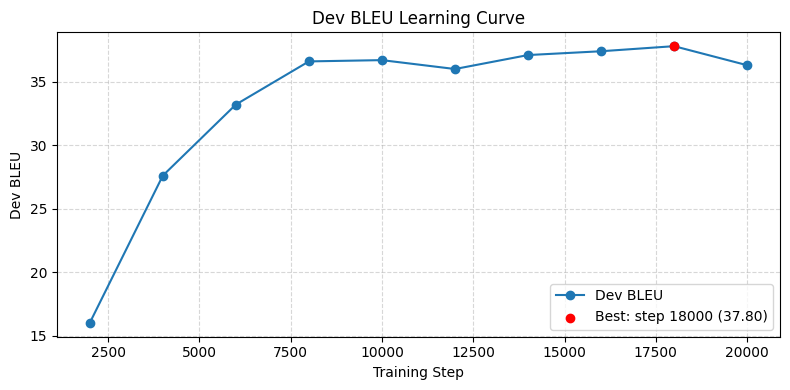

In [13]:
import os
import subprocess
from pathlib import Path
import matplotlib.pyplot as plt

# 2,000ステップ刻みで評価（1,000ステップ刻みにしたい場合は range(1000, 20001, 1000) に変更）
steps = list(range(2000, 20001, 2000))
results = []

for step in steps:
    model_path = Path(f"tanaka/run/model_step_{step}.pt")
    if not model_path.exists():
        print(f"step {step}: チェックポイントが見つからないためスキップします ({model_path})")
        continue
    pred_path = Path(f"pred_step_{step}.txt")
    subprocess.run(
        [
            "onmt_translate",
            "--model", str(model_path),
            "--src", "small_parallel_enja/dev.en",
            "--output", str(pred_path),
        ],
        check=True,
    )
    with pred_path.open("r", encoding="utf-8") as f:
        bleu_out = subprocess.run(
            ["sacrebleu", "-b", "small_parallel_enja/dev.ja"],
            stdin=f,
            capture_output=True,
            text=True,
            check=True,
        )
    score = float(bleu_out.stdout.strip())
    results.append((step, score))
    print(f"step {step:5d}: Dev BLEU = {score:.2f}")

if not results:
    raise RuntimeError("評価可能なチェックポイントが見つかりませんでした。先に学習セルを実行してください。")

best_step, best_bleu = max(results, key=lambda x: x[1])
os.environ["BEST_STEP"] = str(best_step)
print(f"\n最良モデル: model_step_{best_step}.pt (Dev BLEU = {best_bleu:.2f})")

eval_steps, eval_scores = zip(*results)
plt.figure(figsize=(8, 4))
plt.plot(eval_steps, eval_scores, marker="o", label="Dev BLEU")
plt.scatter([best_step], [best_bleu], color="red", zorder=5, label=f"Best: step {best_step} ({best_bleu:.2f})")
plt.xlabel("Training Step")
plt.ylabel("Dev BLEU")
plt.title("Dev BLEU Learning Curve")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
!echo "Best step: ${BEST_STEP}"
!onmt_translate --model "tanaka/run/model_step_${BEST_STEP}.pt" --src small_parallel_enja/test.en --output pred.txt
!sacrebleu small_parallel_enja/test.ja < pred.txt

Best step: 18000


[2026-11-19 02:17:11,297 INFO] Loading checkpoint from tanaka/run/model_step_18000.pt


[2026-11-19 02:17:11,805 INFO] Loading data into the model


[2026-11-19 02:17:14,155 INFO] PRED SCORE: -0.2218, PRED PPL: 1.25 NB SENTENCES: 500
Time w/o python interpreter load/terminate:  2.863464593887329


{
 "name": "BLEU",
 "score": 35.7,
 "signature": "nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0",
 "verbose_score": "63.8/42.9/29.3/21.3 (BP = 0.989 ratio = 0.989 hyp_len = 5574 ref_len = 5635)",
 "nrefs": "1",
 "case": "mixed",
 "eff": "no",
 "tok": "13a",
 "smooth": "exp",
 "version": "2.6.0"
}


## 結果の確認と保存

テストデータの翻訳結果を `pandas.DataFrame` にまとめ、文単位の BLEU スコア（`sacrebleu.sentence_bleu`）を計算して翻訳の傾向を確認します。先頭10文に加えて、文BLEUが低いワースト10文や未知語（`<unk>`）の出現率も確認できます（生のタブ区切りで全件見たい場合は `!paste pred.txt small_parallel_enja/test.{ja,en}` も使えます）。
結果をファイルに保存する場合は `files.download` というメソッドを呼びます。
出力されていない結果は24時間で消えるので、ご注意ください。

In [15]:
from pathlib import Path
import pandas as pd
from IPython.display import display

try:
    import sacrebleu
except ImportError:
    import subprocess
    import sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)
    import sacrebleu

src_lines = Path("small_parallel_enja/test.en").read_text(encoding="utf-8").splitlines()
ref_lines = Path("small_parallel_enja/test.ja").read_text(encoding="utf-8").splitlines()
pred_lines = Path("pred.txt").read_text(encoding="utf-8").splitlines()

assert len(src_lines) == len(ref_lines) == len(pred_lines), (
    f"行数が一致しません: src={len(src_lines)}, ref={len(ref_lines)}, pred={len(pred_lines)}"
)

sent_bleus = [
    round(sacrebleu.sentence_bleu(pred, [ref]).score, 2)
    for pred, ref in zip(pred_lines, ref_lines)
]

df = pd.DataFrame({
    "原文 (en)": src_lines,
    "参照訳 (ja)": ref_lines,
    "システム訳 (pred)": pred_lines,
    "文BLEU": sent_bleus,
})

# <unk> の出現率を集計
unk_sent_count = sum("<unk>" in line.split() for line in pred_lines)
all_tokens = [tok for line in pred_lines for tok in line.split()]
unk_token_count = sum(tok == "<unk>" for tok in all_tokens)
print(f"テスト文数: {len(df)}")
print(f"<unk> を含む文の割合: {unk_sent_count}/{len(df)} ({unk_sent_count / len(df):.1%})")
print(f"<unk> トークンの割合: {unk_token_count}/{len(all_tokens)} ({unk_token_count / max(len(all_tokens), 1):.2%})")

pd.set_option("display.max_colwidth", 80)

print("\n=== 先頭 10 文の翻訳結果 ===")
display(df.head(10))

print("\n=== 文BLEU が低いワースト 10 文 ===")
display(df.sort_values("文BLEU", ascending=True).head(10))

テスト文数: 500
<unk> を含む文の割合: 106/500 (21.2%)
<unk> トークンの割合: 110/5354 (2.05%)

=== 先頭 10 文の翻訳結果 ===


,原文 (en),参照訳 (ja),システム訳 (pred),文BLEU
0,they finally acknowledged it as true .,彼 ら は つい に それ が 真実 だ と 認め た 。,彼 ら は ついに それ を 真実 だ と 認め た 。,50.17
1,he didn 't care for swimming .,彼 は 水泳 が 得意 で は な かっ た 。,彼 は 泳 ぐ 必要 は 無 かっ た 。,18.60
2,he is no less kind than his sister .,彼 は お 姉 さん に 劣 ら ず 親切 だ 。,彼 は お 姉 さん に 劣 ら ず 親切 だ 。,100.00
3,you must be back before ten .,１０ 時 前 に 戻 ら な けれ ば な ら な い 。,１０ 時 前 に 帰 ら な けれ ば な ら な い,70.48
4,break a leg .,成功 を 祈 る わ 。,<unk> に 火 を かけ な さ い 。,4.46
5,she lives next door to us .,彼女 は 私 たち の 隣 の 家 に す ん で い る 。,彼女 は 私 たち の 隣 に 住 ん で い る 。,58.74
6,i 'm about to tell you the answer .,あなた に 返事 を し よ う と し て い る ところ で す 。,あなた に その 答え を 言 う つもり だ 。,5.79
7,i 'm a person who lives for the moment .,私 は 刹那 的 な 生き 方 を し て い る 人間 で す 。,私 は 今 や <unk> に 住 む 人 だ 。,5.43
8,we have this game on ice .,この 試合 は いただ き だ 。,私 たち は この 試合 に 勝 つ こと が でき る 。,7.35
9,will you give me your reasons for doing this ?,こんな こと を し た 理由 を 言 い な さ い 。,君 の こと を これ まで 教え て くれ ま せ ん か 。,6.29



=== 文BLEU が低いワースト 10 文 ===


,原文 (en),参照訳 (ja),システム訳 (pred),文BLEU
291,"three years is a long time , i feel .",３ 年 と い う は 長 い 時間 だ と 私 は 思 う 。,三 年 <unk> に な り ま す 。,2.83
83,he is what we call the man of the hour .,彼 は いわゆる 時 の 人 だ 。,彼 が その 人 を その 人 の <unk> と 呼 ん で い る 。,3.04
289,you need not take the trouble to go .,あえて 行 く に 及 ば な い 。,その 結果 を 考え る 必要 は あ り ま せ ん 。,3.09
326,can you fix him up for the night ?,今晩 泊め て くれ な い か な 。,君 は 彼 を <unk> る こと が 出来 ま す か 。,3.13
307,"if you must , you must .",ぜひ に と あ れ ば 仕方 が な い 。,もし 行 か な けれ ば 、 あなた は 行 き ま す,3.67
460,"sorry , i wish you wouldn 't .",す み ま せ ん 、 ご 遠慮 いただけ ま す か 。,ごめん 、 来 な けれ ば 許 し て くださ い 。,3.71
106,you ask me to do the impossible .,君 は 僕 に な い もの ねだり を し て い る ね 。,あなた は 私 に そんな こと を する よう に する 。,3.73
108,i sometimes look back on the good days i had in london .,ロンドン で 過ご し た 楽し い 日々 の こと を 時々 思い出 す 。,私 は ロンドン に い る よ い 日 を 振り返 る 。,3.75
366,give me the details of it .,その 内訳 は ？,その <unk> の <unk> を くれ 。,3.75
434,it 's touch and go .,どちら に 転 ぶ か 、 微妙 な ところ で す 。,それ は 明らか に 行 く 。,3.82


In [ ]:
from google.colab import files
files.download("pred.txt")